In [1]:
%cd ..

d:\Courses\Route\LLMOPs\1st_assignment\ML-Production_Project


# Importing Libraries

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from imblearn.combine import SMOTETomek
import joblib

# Importing the dataset

In [3]:
df = pd.read_csv(r'notebooks\kaggle\breast-cancer.csv')

# EDA

**Note on data leakage:** The EDA plots below (class-colored distributions and the target-correlation chart) use the **full** dataset, including rows that later end up in the test set. That is acceptable for building understanding, but nothing here may drive feature or model selection - those decisions are evaluated only on the held-out test set after the split.

## Taking a look at a sample from our data

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Checking for Null-Values and inappropriate data types

In [5]:
df.isna().sum()

id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

We don't have any null values. So, we don't need to think about removing/replacing any values in the rows nor columns we have.

---


The data type matches our values. Therefore, there's no reason to convert any column to another dtype.

## Removing Unnecessary columns

In [7]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='str')

In [8]:
df.drop(['id'], axis=1, inplace=True)

In [9]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Renaming the Diagnosis terms

In [10]:
df['diagnosis'] = df['diagnosis'].replace({'M': 'malignant', 'B': 'benign'})


In [11]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,malignant,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,malignant,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,malignant,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,malignant,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,malignant,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Checking for Potential Outliers using (describe function)

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


## Checking the Frequency for both cases

In [13]:
fig = px.histogram(
    df,
    x="diagnosis",
    color="diagnosis",
    text_auto=True,
    color_discrete_sequence=["#6D213C", "#8AAA79"],
)
fig.show()


**📈 Why this chart matters — class balance.** 357 benign vs 212 malignant (≈63/37): a mild but real skew. It is the reason `SMOTETomek` is applied to the training fold later — without it the model could lean toward the majority class and under-call malignant cases.

## Checking the distribution for the values in the dataset (using Visualization graphs)

This mainly helps us in identifying outliers **graphically**. If any where to be found.

In [14]:
fig = px.histogram(
    df,
    x="radius_mean",
    color="diagnosis",
    histnorm="probability density",
    opacity=0.6,
    color_discrete_sequence=["#6D213C", "#8AAA79"],
)
fig.update_layout(barmode="overlay")
fig.show()


**What to look for —** the malignant distribution is shifted toward larger radii, but the two curves overlap heavily: any single feature separates the classes only partially, which is why the final model combines all of them.

In [15]:
fig = px.histogram(
    df,
    x="concavity_mean",
    color="diagnosis",
    histnorm="probability density",
    opacity=0.6,
    color_discrete_sequence=["#6D213C", "#8AAA79"],
)
fig.update_layout(barmode="overlay")
fig.show()


**What to look for —** deeper concavities skew malignant, yet the overlap is strong. This feature is weak *on its own* — its value comes from being weighted together with the rest.

In [16]:
fig = px.histogram(
    df,
    x="concave points_mean",
    color="diagnosis",
    histnorm="probability density",
    opacity=0.6,
    color_discrete_sequence=["#6D213C", "#8AAA79"],
)
fig.update_layout(barmode="overlay")
fig.show()


**What to look for —** the clearest single-feature separation here: the benign mass concentrates near zero while malignant spreads right. It also tops the correlation ranking below — the visual intuition and the numbers agree.

In [17]:
fig = px.histogram(
    df,
    x="area_worst",
    color="diagnosis",
    histnorm="probability density",
    opacity=0.6,
    color_discrete_sequence=["#6D213C", "#8AAA79"],
)
fig.update_layout(barmode="overlay")
fig.show()


**What to look for —** the largest class gap of the four, but also a range spanning three orders of magnitude — feature scales differ drastically, which is exactly why `StandardScaler` is a pipeline step rather than an optional nicety.

In [18]:
fig = px.box(
    df,
    x="diagnosis",
    y="concavity_worst",
    color="diagnosis",
    color_discrete_sequence=["#6D213C", "#8AAA79"],
)
fig.show()


**What to look for —** the malignant box sits higher (median and upper quartiles) and the most extreme dots are malignant cases. Those outliers are informative rare tumors, not junk to clip or drop.

In [19]:
fig = px.box(
    df,
    x="diagnosis",
    y="radius_worst",
    color="diagnosis",
    color_discrete_sequence=["#6D213C", "#8AAA79"],
)
fig.show()


**What to look for —** malignant tumors are both larger on average *and* more variable. The spread itself carries signal — another argument for scaling the features instead of clipping their extremes.

In [20]:
fig = px.scatter(
    df,
    x="radius_worst",
    y="concavity_worst",
    color="diagnosis",
    opacity=0.7,
    color_discrete_sequence=["#6D213C", "#8AAA79"],
)
fig.show()


**📈 Why this chart matters — joint separation.** Malignant cases cluster in the upper-right, benign in the lower-left; two features together already almost split the classes. That is the empirical justification for choosing a linear model (Logistic Regression) — the small overlap band is where the few test errors are expected to come from.

# Data Preprocessing

## Finding the highly correlated data with our Target

Since `diagnosis` is categorical, we need to encode it to numeric values before computing correlations. Because it is **binary** (benign vs malignant), plain label encoding (`benign=0`, `malignant=1`) is enough. One-Hot Encoding would add a second column that is the exact mirror of the first (perfectly negatively correlated), which only duplicates information - we will not use it here.

In [21]:
df["diagnosis_num"] = df["diagnosis"].map({"benign": 0, "malignant": 1})
df["diagnosis_num"].value_counts()


diagnosis_num
0    357
1    212
Name: count, dtype: int64

In [22]:
corr_target = (
    df.corr(numeric_only=True)["diagnosis_num"]
    .drop("diagnosis_num")
    .abs()
    .sort_values()
)
top10 = (
    corr_target.tail(10)
    .rename("abs_corr")
    .reset_index()
    .rename(columns={"index": "feature"})
)

fig = px.bar(
    top10,
    x="abs_corr",
    y="feature",
    orientation="h",
    title="Top 10 features most correlated with diagnosis (malignant=1)",
    color_discrete_sequence=["#6D213C"],
)
fig.update_layout(xaxis_title="|correlation|", yaxis_title="feature")
fig.show()


**📈 Why this chart matters — feature ranking.** Each bar is a feature's absolute linear correlation with the encoded target: `concave points_worst` leads, and the `*_worst` / `*_mean` / `*_se` variants of the same measurement cluster together (redundancy the model handles by weighting). Reminder from the caveat above: this ranks association for understanding — it is not a feature-selection step.

The strongest single correlate is **`concave points_worst`**. Also note that the worst/mean/se variants of radius, perimeter and area all land in the top 10 - they measure the same thing (perimeter is roughly 2*pi*radius), so this is multicollinearity, not 10 independent signals. Logistic regression is robust to that; tree models typically pick one and ignore the rest.

## Splitting the data using Train Test Split

The "train_test_split() method" is used to split our data into train and test sets.

---

First, we need to divide our data into features (X) and labels (y). The dataframe gets divided into X_train,X_test , y_train and y_test. X_train and y_train sets are used for training and fitting the model. The X_test and y_test sets are used for testing the model if it's predicting the right outputs/labels. we can explicitly test the size of the train and test sets. It is suggested to keep our train sets larger than the test sets.


* **Train set:** The training dataset is a set of data that was utilized to fit the model. The dataset on which the model is trained. This data is seen and learned by the model.

* **Test set:** The test dataset is a subset of the training dataset that is
utilized to give an accurate evaluation of a final model fit.

* **validation set:**  A validation dataset is a sample of data from your model's training set that is used to estimate model performance while tuning the model's hyperparameters.

In [23]:
X = df.drop(columns=["diagnosis", "diagnosis_num"]).values
y = df["diagnosis_num"].values


In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Data Sampling

In [25]:
# Intializing our data sampling algorithm
smt = SMOTETomek(random_state=42)
X_train_bal, y_train_bal = smt.fit_resample(X_train, y_train)

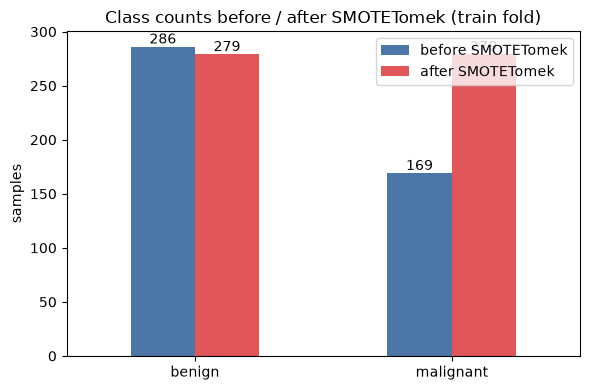

In [26]:
# Visual check: class balance before vs after SMOTETomek (train fold only; the test fold is left untouched)
counts = pd.DataFrame(
    {
        "before SMOTETomek": pd.Series(y_train).value_counts(),
        "after SMOTETomek": pd.Series(y_train_bal).value_counts(),
    }
).sort_index()
counts.index = ["benign", "malignant"]

ax = counts.plot(kind="bar", figsize=(6, 4), rot=0, color=["#4C76A5", "#E15759"])
ax.set_title("Class counts before / after SMOTETomek (train fold)")
ax.set_xlabel("")
ax.set_ylabel("samples")
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.tight_layout()
plt.show()

**📈 Why this chart matters — sampling check.** The bars show the training fold's class counts before and after `SMOTETomek`: the original ≈63/37 skew becomes balanced, while the test fold is deliberately left untouched so evaluation stays realistic. Balance is the point of the sampler — it stops the model from defaulting to the majority class; it does **not** manufacture extra separation between the classes — that still has to come from the features.

#### 📊 What Is Data Sampling in Machine Learning?

In machine learning, **data sampling** refers to techniques used to adjust the **class distribution** within a dataset. This becomes crucial when handling **imbalanced datasets**, such as in **breast cancer detection**, where one class (e.g., **benign tumors**) significantly outnumbers the other (e.g., **malignant tumors**). 

Such imbalance can lead models to become biased toward the majority class, resulting in poor detection of malignant cases — which are **clinically more critical**.

---

## ⚖️ Why Is Sampling Important?

Imbalanced datasets can cause several issues:

- **Biased Predictions**: Models may favor the majority class (benign), ignoring the minority class (malignant).
- **Misleading Accuracy**: High overall accuracy might hide the fact that the model rarely predicts malignant tumors correctly.
- **Poor Generalization**: The model may not learn the features of malignant tumors effectively.

To address these issues, sampling techniques are used to balance the class distribution and help the model learn more fairly from both classes.

---

## 🔄 Common Sampling Techniques

1. **Oversampling**: Increases the number of malignant samples.  
   - *Example*: **SMOTE (Synthetic Minority Over-sampling Technique)** generates synthetic malignant samples by interpolating between existing ones.

2. **Undersampling**: Reduces the number of benign samples.  
   - *Example*: Randomly removes benign samples to create a more balanced dataset.

3. **Combination of Both**: Uses both oversampling and undersampling for more robust balance.  
   - *Example*: **SMOTETomek**, which combines SMOTE with Tomek Links.

---

## ✅ Why Did We Use SMOTETomek?

**SMOTETomek** is a hybrid technique that offers the benefits of both oversampling and undersampling:

- **SMOTE** creates synthetic samples to increase malignant class representation.
- **Tomek Links** remove overlapping or noisy examples near the benign/malignant decision boundary.

This approach improves class balance while also cleaning up the dataset, leading to better model generalization and more reliable detection of malignant tumors.

---

## 📌 Summary of Benefits

Using SMOTETomek helps:

- ✅ Improve detection of malignant tumors (recall and precision).
- ✅ Clean noisy or overlapping examples near decision boundaries.
- ✅ Ensure the model learns from both benign and malignant cases fairly.

---

🔗 [Learn more from GeeksforGeeks](https://www.geeksforgeeks.org/how-to-handle-imbalanced-classes-in-machine-learning/)


## Standarizing our data for more efficient processing

## StandardScaler Vs Normalizer
StandardScaler standardizes features by removing the mean and scaling to unit variance. It transforms the data to have a mean of 0 and a standard deviation of 1. This process is also known as z-score normalization.

---

Why Use Standardization in Machine Learning?

- Mean Centering: Standardization centers the data by subtracting the mean from each feature. This ensures that the transformed data has a mean of 0. Mean centering is crucial because it helps in capturing the relative variations in the data.

- Scale Invariance: Standardization scales the data by dividing each feature by its standard deviation. This makes the data scale-invariant, meaning that the scale of the features no longer affects the performance of many machine learning algorithms. Without standardization, features with larger scales may dominate the learning process.

- Improved Convergence: Many machine learning algorithms, such as gradient-based optimization algorithms (e.g., gradient descent), converge faster when the features are standardized. It reduces the potential for numerical instability and overflow/underflow issues during training.

- Comparability: Standardizing the features makes it easier to compare and interpret the importance of each feature. This is especially important in models like linear regression, where the coefficients represent the feature's impact on the target variable.

- Regularization: In regularization techniques like Ridge and Lasso regression, the regularization strength is applied uniformly to all features. Standardization ensures that the regularization term applies fairly to all features.

---


The StandardScaler transformation is given by:

$$
X_{\text{scaled}} = \frac{X - \mu}{\sigma}
$$

Where:  
- $( X $) is the original feature value.  
- $( \mu $) is the mean of the feature.  
- $( \sigma $) is the standard deviation of the feature.

---

## Normalizer

**Normalizer** scales individual samples to have unit norm. It transforms each sample (row) into a unit vector, preserving the direction of the data while scaling.

For each sample $x$:

$$
x' = \frac{x}{\|x\|}
$$

Where $\|x\|$ is the **norm** of the vector $x$. The default norm used is **L2 norm** (Euclidean distance), but you can specify **L1** or **max norms** as well.

### **When to Use Normalizer?**
- **High-Dimensional Sparse Data**: Useful for text classification, image processing, or any case where the focus is on the **direction** of the data points.
- **Data with Varying Magnitudes**: When the magnitude of the feature vectors matters less than their direction.

[More about it](https://www.geeksforgeeks.org/difference-between-standardscaler-and-normalizer-in-sklearn-preprocessing/?ref=ml_lbp)

I will use the **StandardScaler** to scale this dataset, as it achieved a better overall accuracy score compared to the **Normalizer**.

In [27]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_bal)
X_test_scaled = scaler.transform(X_test)

# Model Implementation

## Logistic Regression

## What is Logistic Regression?

---

Logistic regression is a supervised machine learning algorithm used for classification tasks where the goal is to predict the probability that an instance belongs to a given class or not. Logistic regression is a statistical algorithm which analyze the relationship between two data factors. The article explores the fundamentals of logistic regression, it’s types and implementations.

Logistic regression is used for binary classification where we use sigmoid function, that takes input as independent variables and produces a probability value between 0 and 1.

For example, we have two classes Class 0 and Class 1 if the value of the logistic function for an input is greater than 0.5 (threshold value) then it belongs to Class 1 otherwise it belongs to Class 0. It’s referred to as regression because it is the extension of linear regression but is mainly used for classification problems.

Key Points:
- Logistic regression predicts the output of a categorical dependent variable. Therefore, the outcome must be a categorical or discrete value.
- It can be either Yes or No, 0 or 1, true or False, etc. but instead of giving the exact value as 0 and 1, it gives the probabilistic values which lie between 0 and 1.
- In Logistic regression, instead of fitting a regression line, we fit an “S” shaped logistic function, which predicts two maximum values (0 or 1).

In [28]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train_bal)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

## Classification Report Metrics

A classification report is needed to evaluate the performance of a classification model. It provides key metrics like precision, recall, F1-score, and support, helping us understand how well the model distinguishes between classes. This is crucial for identifying imbalances, improving predictions, and making informed decisions based on model performance.

---
- **Precision** (also called positive predictive value) is how many of the predicted positive instances are actually correct. It is useful when false positives are costly  
Written as a formula:

$$
\text{Precision} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Positives}}
$$

---
- **Recall** (also known as sensitivity) is how many actual positive instances were correctly identified. It is important when false negatives need to be minimized  
Written as a formula:

$$
\text{Recall (Sensitivity)} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}}
$$


***Both precision and recall are therefore based on relevance.***

---

- **F1 score** can be interpreted as a harmonic mean of the precision and recall, where an F1 score reaches its best value at 1 and worst score at 0. The relative contribution of precision and recall to the F1 score are equal. The formula for the F1 score is:

$$
F1\text{-}Score = \frac{2 \times \text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}
$$

---
- **Support** is the number of actual occurrences of each class in the dataset. It shows how many true samples belong to each class, helping assess class imbalance and model performance.



#### ⚠ Model Update

In [29]:
model_scores = {}

# Saving the model

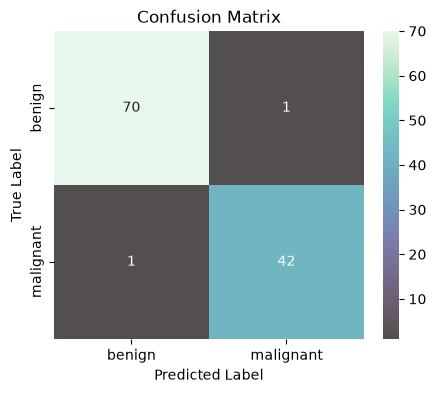

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99        71
           1       0.98      0.98      0.98        43

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [30]:
# Predict and evaluate the first model
y_pred = model.predict(X_test_scaled)

cm_matrix = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm_matrix,
    cmap="mako",
    alpha=0.7,
    annot=True,
    xticklabels=["benign", "malignant"],
    yticklabels=["benign", "malignant"],
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

# Print classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

# Store in dict
model_scores = {}

acc = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)
cm = confusion_matrix(y_test, y_pred)

model_scores["Logistic Regression"] = {
    "model": model,
    "y_pred": y_pred,
    "accuracy": acc,
    "report": report,
    "confusion_matrix": cm
}


**📈 How to read this —** the diagonal counts correct predictions; off-diagonal cells are errors *by type*. Benign called malignant (false positive) triggers unnecessary concern; malignant called benign (false negative) **misses a cancer** — the costly direction. That is why recall on the malignant class, not accuracy, is the headline metric everywhere in this project, including the production logs.

In [31]:
joblib.dump(model, r"models\joblib_models\logistic_regression.pkl")

['models\\joblib_models\\logistic_regression.pkl']

# ⚠️Code Update

## Applying more models to our model training process

In [32]:
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss'),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes Gaussian": GaussianNB(),
    "Support Vector Classifier": SVC(),
    "K-Nearest Neighbors": KNeighborsClassifier()
}

### 🔍 Overview of Classification Models Used

### 1. Random Forest

**Purpose**: An ensemble of decision trees that combines multiple trees trained on random subsets of the data and features.

**How It Works**:
- Each tree votes for a class.
- The majority vote is taken as the final prediction.

**Strengths**: Handles high-dimensional data well, reduces overfitting through averaging.

---

### 2. XGBoost (Extreme Gradient Boosting)

**Purpose**: A powerful gradient boosting algorithm that builds trees sequentially to correct the errors of previous trees.

**Core Idea**:
- Uses gradient descent to minimize a loss function.
- Regularization is built in to prevent overfitting.

**Objective Function**:

$$
\mathcal{L} = \sum_{i=1}^{n} l(y_i, \hat{y}_i^{(t)}) + \sum_{k=1}^{t} \Omega(f_k)
$$

Where $( \Omega(f_k) )$ penalizes the complexity of each tree.

**Strengths**: Fast, efficient, excellent performance on structured/tabular data.

---

### 3. Decision Tree

**Purpose**: A tree-like structure where each internal node represents a decision rule, and each leaf node represents a class label.

**How It Works**:
- Splits data based on feature thresholds to maximize information gain or reduce Gini impurity.

**Gini Impurity Equation**:

$$
G = 1 - \sum_{i=1}^{C} p_i^2
$$

Where $( p_i )$ is the probability of class $( i )$ at a node.

**Strengths**: Easy to visualize, interpretable, handles both numerical and categorical data.

---

### 4. Naive Bayes (Gaussian)

**Purpose**: A probabilistic model based on Bayes' Theorem with the assumption of feature independence.

**Bayes' Theorem**:

$$
P(y \mid x) = \frac{P(x \mid y) P(y)}{P(x)}
$$

For Gaussian NB, it assumes:

$$
P(x_i \mid y) \sim \mathcal{N}(\mu_{y}, \sigma_{y}^2)
$$

**Strengths**: Fast, works well with text data and high-dimensional inputs.

---

### 5. K-Nearest Neighbors (KNN)

**Purpose**: A non-parametric algorithm that classifies a sample based on the majority label among its $( k )$ nearest neighbors.

**Distance Metric (Euclidean)**:

$$
d(x, x_i) = \sqrt{ \sum_{j=1}^{n} (x_j - x_{ij})^2 }
$$

**Strengths**: Simple, effective for low-dimensional and well-separated data.

---

These models provide a diverse set of approaches—linear, tree-based, probabilistic, and instance-based—allowing for a well-rounded evaluation on the classification task.


## New models Training

In [33]:
for name, model in models.items():
    model.fit(X_train_scaled, y_train_bal)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    cm = confusion_matrix(y_test, y_pred)

    model_scores[name] = {
        "model": model,
        "y_pred": y_pred,
        "accuracy": acc,
        "report": report,
        "confusion_matrix": cm
    }

    print(f"--- {name} ---")
    print("Accuracy:", acc)
    print("Confusion Matrix:\n", cm)
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("=======================================================")
    print("\n")


--- Random Forest ---
Accuracy: 0.9649122807017544
Confusion Matrix:
 [[69  2]
 [ 2 41]]
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.97      0.97        71
           1       0.95      0.95      0.95        43

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



--- XGBoost ---
Accuracy: 0.9649122807017544
Confusion Matrix:
 [[70  1]
 [ 3 40]]
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.99      0.97        71
           1       0.98      0.93      0.95        43

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



--- Decision Tree ---
Accuracy: 0.956140350877193
Confusion Matrix:
 [[68  3]
 [ 2 41]]
Classification Report:
           

## Plotting different models performance

### Confusion matrix

#### 📊 What is a Confusion Matrix?

A **confusion matrix** is a performance evaluation table used for classification problems.  
It compares the predicted labels from your model to the actual true labels.

---

### 📦 Layout of the Confusion Matrix:

```
                Actual
               0       1
Predicted  ┌──────────────┐
     0     │  TN    |  FN │
     1     │  FP    |  TP │
           └──────────────┘
```

- **TN (True Negative):** Model predicted 0, and the actual was 0.
- **TP (True Positive):** Model predicted 1, and the actual was 1.
- **FP (False Positive):** Model predicted 1, but the actual was 0 (false alarm).
- **FN (False Negative):** Model predicted 0, but the actual was 1 (missed it).

---

### ✅ Why It Matters:

The confusion matrix helps you calculate key metrics like:
- **Accuracy:** Overall correctness → `(TP + TN) / Total`
- **Precision:** Correctness of positive predictions → `TP / (TP + FP)`
- **Recall (Sensitivity):** Ability to find all actual positives → `TP / (TP + FN)`
- **F1-Score:** Balance between precision and recall → `2 * (Precision * Recall) / (Precision + Recall)`

Use it to understand not just how often your model is right — but **how** it is right or wrong.


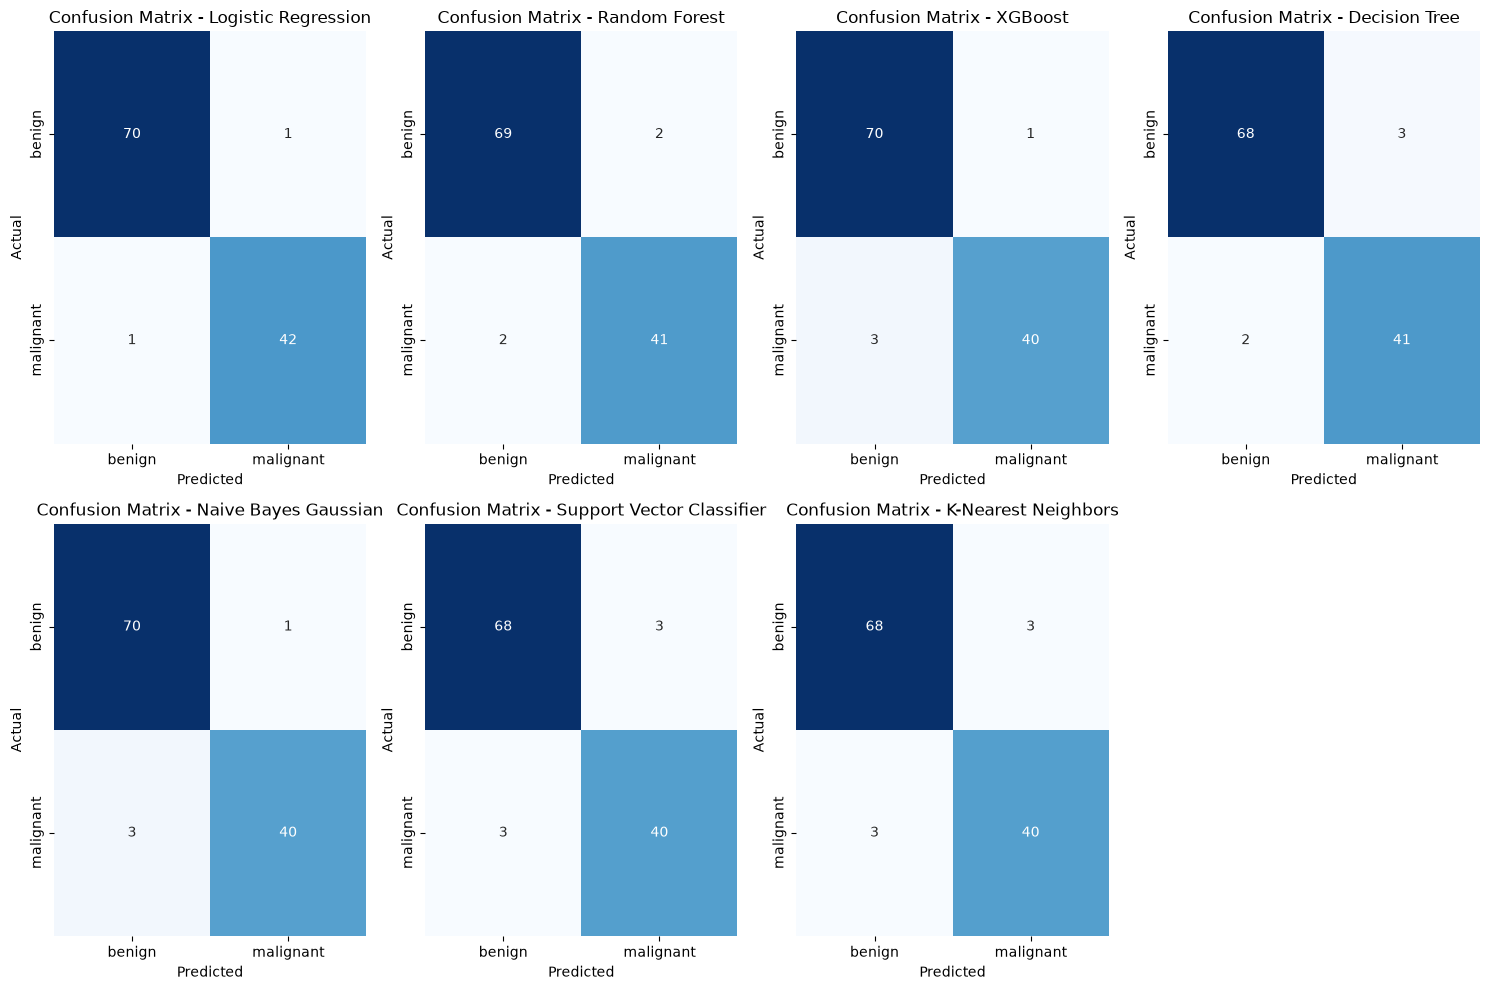

In [34]:
num_models = len(model_scores)
cols = 4
rows = -(-num_models // cols)  # ceiling division without importing math module

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()

for idx, (name, info) in enumerate(model_scores.items()):
    sns.heatmap(
        info["confusion_matrix"],
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes[idx],
        xticklabels=["benign", "malignant"],
        yticklabels=["benign", "malignant"],
    )
    axes[idx].set_title(f"Confusion Matrix - {name}")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

# Turn off any unused subplots
for ax in axes[num_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


**📈 Why this chart matters — error fingerprints.** One confusion matrix per model, side by side: two models with identical accuracy can fail in different places. Comparing *where* the errors land — especially false negatives — is what separates picking a model from merely ranking one.

### Bar Plot (Accuracy, Precision, Recall, F1-Score)

#### 🔍 Evaluation Metrics Explained (Simple + Math)

#### ✅ Accuracy
**Meaning:** How many predictions the model got totally right out of all predictions.

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

---

#### ✅ Precision
**Meaning:** Out of everything predicted as **positive**, how many were *actually* positive?

$$
\text{Precision} = \frac{TP}{TP + FP}
$$

---

#### ✅ Recall (Sensitivity)
**Meaning:** Out of all the **actual positives**, how many did the model *correctly find*?

$$
\text{Recall} = \frac{TP}{TP + FN}
$$

---

#### ✅ F1-Score
**Meaning:** A balance between Precision and Recall — high only when both are high.

$$
\text{F1-Score} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
$$


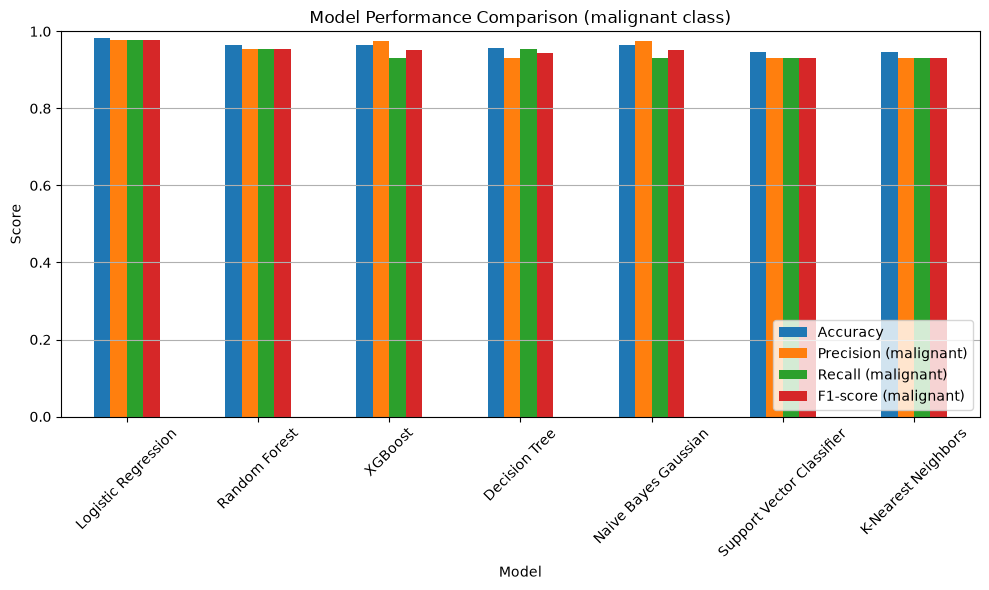

In [35]:
plot_data = [
    {
        "Model": name,
        "Accuracy": info["accuracy"],
        "Precision (malignant)": info["report"]["1"]["precision"],
        "Recall (malignant)": info["report"]["1"]["recall"],
        "F1-score (malignant)": info["report"]["1"]["f1-score"],
    }
    for name, info in model_scores.items()
]

scores_df = pd.DataFrame(plot_data)
ax = scores_df.set_index("Model")[
    [
        "Accuracy",
        "Precision (malignant)",
        "Recall (malignant)",
        "F1-score (malignant)",
    ]
].plot(kind="bar", figsize=(10, 6))

plt.title("Model Performance Comparison (malignant class)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


**📈 Why this chart matters — full metric profile.** All four metrics on one axis: accuracy alone can look fine while recall on the malignant class quietly suffers. The model choice therefore rests on the whole profile (accuracy, precision, recall, F1) — which is also exactly what the production app logs on every training run.

## Saving our models

In [36]:
output_dir = r'models\joblib_models'

for name, model in models.items():

    joblib.dump(model, f"{output_dir}/{name.replace(' ', '_')}.pkl")

    print(f"✔ Saved: {name}")

✔ Saved: Random Forest
✔ Saved: XGBoost
✔ Saved: Decision Tree
✔ Saved: Naive Bayes Gaussian
✔ Saved: Support Vector Classifier
✔ Saved: K-Nearest Neighbors


# Conclusion

## ✅ Project Conclusion: Breast Cancer Classification with Balanced Sampling and Supervised Models

In this project, we successfully developed a breast cancer classification pipeline using multiple supervised learning models, enhanced with data balancing and feature scaling techniques. The primary goal was to accurately distinguish between malignant and benign tumors, with special emphasis on improving sensitivity to malignant cases — the minority and clinically critical class.

---

### 🎯 Key Achievements:

- **Data Preprocessing**:
  - Removed irrelevant features (e.g., `id`)
  - Verified data integrity (no missing values)
  - Encoded target labels using one-hot encoding
  - Scaled features using `StandardScaler` for optimal model performance

- **Class Balancing**:
  - Addressed class imbalance using `SMOTETomek` (oversampling + undersampling)
  - Ensured fair model training by balancing malignant and benign samples

- **Model Training and Evaluation**:
  - Trained multiple models: Logistic Regression, Random Forest, Decision Tree, Naive Bayes, KNN, SVC, XGBoost
  - Evaluated using Accuracy, Precision, Recall, F1-Score, and Confusion Matrices
  - Focused on the malignant class (class 1) to reduce false negatives

---

### 📈 Visual Analytics:

- Plotted confusion matrices for all models in a grid layout
- Compared model metrics using bar plots (Accuracy, Precision, Recall, F1-Score)

---

### 💡 Future Work:

- Apply `GridSearchCV` and cross-validation for model tuning
- Experiment with deep learning techniques for advanced classification

---

This project highlights the importance of robust preprocessing, balanced training, and diverse model evaluation in building accurate and clinically meaningful diagnostic tools.
